# Policy Function Iteration

**Seong Cho** · ACME Volume 2, Lab 19

**Lab objective:** learn how iterative methods can be used to solve dynamic optimization problems, implementing value iteration and policy iteration in a pseudo-infinite setting where finite value iteration is intractable.

<sub>Lab specification from the *Volume 2* lab manual of [Foundations of Applied Mathematics](https://foundations-of-applied-mathematics.github.io/) (BYU ACME), © Dr. J. Humpherys, used under [CC BY 3.0 US](http://creativecommons.org/licenses/by/3.0/us/). Problem statements are quoted from the spec; the notes are condensed from it. Solutions are my own.</sub>

In [1]:
import numpy as np
import scipy.linalg as la
import time
import matplotlib.pyplot as plt

Iterative methods can solve dynamic optimization problems quickly, converging to the true solution or to within some $\varepsilon$ of it, and they are significantly faster than computing the exact solution with dynamic programming. This lab solves the dynamic cake-eating problem with two of them: infinite value function iteration, often just called *value iteration* (VI), and infinite policy function iteration, also called *policy iteration* (PI).

## Infinite Value Iteration

In finite dynamic optimization we solve

$$\max_{c_t} \sum_{t=0}^T \beta^t u(c_t) \quad \text{subject to} \quad \sum_{t=0}^T c_t = W_{max}, \quad c_t \ge 0.$$

For some problems $T$ is unknown or extremely large. When $T$ is large, $\beta$ must be close to 1, otherwise $\beta^t$ rapidly approaches zero: in 100 time steps $(0.9)^{100} \approx 2.65\text{e-}5$, whereas $\beta = 0.999$ does not get that low until around $t = 10500$. So even if $T$ is large, we are usually constrained by our choice of $\beta$, because eventually $\beta^t \to 0$.

In the previous lab, the value function $V(W)$ was the maximum utility that comes from having $W$ cake. By Bellman's equation,

$$V(w_i) = \max_{c \in [0, w_i]} u(c) + \beta V(w_i - c). \tag{19.1}$$

Substituting $w_i' = w_i - c$ gives

$$V(w_i) = \max_{w_i' \in [0, w_i]} u(w_i - w_i') + \beta V(w_i'). \tag{19.2}$$

In (19.1), $c$ is the *action* to take when we have $w_i$ cake (how much to consume); in (19.2), $w_i'$ is the *state* we will be in at the next period (how much to save).

A contraction mapping $f$ has a fixed point $p$ with $f(p) = p$. Blackwell's contraction theorem shows that Bellman's equation is a "fixed point" (it acts more like a fixed function here) of the operator $T : L^\infty(X; \mathbb{R}) \to L^\infty(X; \mathbb{R})$ on the set of all bounded functions,

$$[T(f)](w) = \max_{w' \in [0, w]} u(w - w') + \beta f(w'). \tag{19.3}$$

(19.2) is the fixed point of $T$, and (19.3) has a unique solution. The fixed point of a contraction mapping can be found by applying it repeatedly to any starting point: $f^M(x) = f \circ f \circ \cdots \circ f(x) = p$ for some $M$ that depends on the initial guess and on the contraction's discount factor, here $V_0$ and $\beta$. So the true value function $V^*(w)$ is the limit of

$$V_{k+1}(w_i) = [T(V_k)](w_i) = \max_{w' \in [0, w_i]} u(w_i - w') + \beta V_k(w') \quad \forall w_i, \tag{19.4}$$

from an initial guess $V_0(w)$; as $k \to \infty$, $V_k(w) \to V^*(w)$, and if $V_{k+1}(w) = V_k(w)$ for all $w$ we have found $V^*(w)$. The *value iteration* algorithm:

1. Discretize the space into $N$ equal sized pieces: $\mathbf{w} = [w_0, w_1, \ldots, w_N]$, where $w_0 = 0$, $w_N = W_{max}$. $w_i$ is the value when there are $i$ pieces of cake remaining.
2. Choose an initial vector to represent $V_0$: $[V_0(w_0), V_0(w_1), \ldots, V_0(w_N)]$. A common initial choice is $V_0(w_i) = u(w_i)$.
3. For $k = 1, 2, \ldots,$ `max_iter`:
    1. For each $w_i \in \mathbf{w}$: calculate $V_{k+1}(w_i) = \max_{w' \in \mathbf{w} \,|\, w' \le w_i} u(w_i - w') + \beta V_k(w')$.
    2. If $\|V_{k+1} - V_k\| < \varepsilon$, terminate early.

The `max_iter` parameter stops the algorithm regardless of convergence, since a guaranteed but slow convergence rate might not be useful. Generally, though, this algorithm converges much faster than computing the true value function with dynamic programming as in Finite Value Iteration.

> **Achtung!** Here $w'$ represents how much cake to leave for the next period, not a derivative of $w$. Also note that $w' \le w_i$, because we can never have more cake at a later period; cake can only be consumed, not created.

## Problem 1: Value iteration

> **Problem 1.** Write a function called `value_iteration()` that will accept a numpy array representing the initial vector $V_0$, a discount factor $\beta \in (0, 1)$, the number of states to split $\mathbf{w}$ into $N$, the amount of initial cake $W_{max}$, a utility function $u(x)$, the tolerance amount $\varepsilon$, and the maximum number of iterations `max_iter`. Perform value iteration until $\|V_{k+1} - V_k\| < \varepsilon$ or $k >$ `max_iter`. Return the final vector representing $V^*$.
>
> It is useful for our function to accept $V_0$ as a parameter instead of calculating an initial guess inside our function, so that we can try different initial states for $V_0$.
>
> Test your function with the parameters $N = 400$, $\beta = .995$, $u(x) = \sqrt{x}$, $W_{max} = 1$. Try different values for $V_0$ and see if you get the same value for $V^*(W_{max})$ (The value should be approximately 9.4988). How do different initial guesses for $V_0$ affect the number of iterations required for convergence?

My `value_iteration()` is the finished version from Problem 3, which also returns the policy vector through `extract_policy_vector()` (Problem 2). It is defined and tested under Problem 3, after that helper.

## The Policy Function

$V^*(W_{max})$ is the optimal value for our problem,

$$V^*(W_{max}) = \max_{c_t} \sum_{t=0}^T \beta^t u(c_t) \quad \text{subject to} \quad \sum_{t=0}^T c_t = W_{max}, \quad c_t \ge 0,$$

but it is usually more important to know which sequence $(c_t)_{t=0}^T$ yields it: the policy vector $\mathbf{c} = [c_0, c_1, \ldots, c_T]$, eating $c_i$ cake at time $t = i$. In a truly infinite problem $\mathbf{c}$ would be impossible to calculate, but in the cake-eating problem there are never more than $N$ time periods: it is never optimal to eat 0 pieces of cake in a single time period, since the discount factor $\beta$ means at least 1 piece must be eaten at each step. The length of $\mathbf{c}$ depends on $\beta$: when $\beta = 0$ only the first time period matters, so $T = 0$ and $\mathbf{c}$ has length 1, and as $\beta$ gets closer to 1, $T$ increases as well.

The *policy function* $\pi : \mathbb{R} \to \mathbb{R}$, with $0 \le \pi(w_i) \le w_i$ for all $i$, gives the amount of cake to save for the next period when we start with $w_i$ cake. Modifying the Bellman equation with $V^*$,

$$\pi(w_i) = \underset{w_i' \in \mathbf{w} \,|\, w_i' \le w_i}{\operatorname{argmax}} \; u(w_i - w_i') + \beta V^*(w_i') \quad \forall i. \tag{19.5}$$

In practice $\pi$ is represented as a vector: $\pi_i$ is how many pieces of cake to save for the next period if we currently have $i$ pieces. For example, $\pi(W_{max}) = w_4$ is represented by $\pi[N] = 4$. The policy vector then follows from

$$c_t = w^{(t)} - \pi(w^{(t)}), \qquad w^{(t+1)} = \pi(w^{(t)}), \qquad w^{(0)} = W_{max}.$$

> **Achtung!** $w^{(t)}$ represents a time index, how much cake we have at time $t$, not to be confused with $w_i$, the numeric value of having $i$ pieces.

## Problem 2: Extracting the policy vector

> **Problem 2.** Write a helper function called `extract_policy_vector()` that will accept an array of discretized values $\mathbf{w}$, and a vector representing a policy function $\pi$. Return the policy vector $\mathbf{c}$ that determines how much cake should be eaten at each time step.
>
> Test your function with $\mathbf{w} = [0, .1, .2, \ldots, 1]$ and $\pi = [0, 0, 1, 2, 2, 3, 3, 4, 4, 5, 5]$. The resulting policy vector should be $\mathbf{c} = [0.5, 0.2, 0.1, 0.1, 0.1]$.

In [2]:
def extract_policy_vector(possible_W, policy_function):
    """Returns the policy vector that determines how much cake should be eaten at each time step

    Parameters:
        possible_W (ndarray) - an array representing the discrete values of W
        policy_function (ndarray) - an array representing how many pieces to leave at each state

    Returns:
        c (list) - a list representing how much cake to eat at each time period
    """
    n = len(possible_W)-1
    W_max = possible_W[-1]
    w1 = possible_W[1]
    c = []
    w = sum(c)
    # Stopping criteria
    while not np.isclose(w, W_max):
        wi = W_max - w
        eat = policy_function[int(round(wi*n))]
        # Keep track of how much cake is eaten each iteration
        c.append(wi - w1*eat)
        w = sum(c)
    return c

In [3]:
c = extract_policy_vector(np.linspace(0, 1, 11), [0, 0, 1, 2, 2, 3, 3, 4, 4, 5, 5])
print(np.array(c))
assert np.allclose(c, [0.5, 0.2, 0.1, 0.1, 0.1])

[0.5 0.2 0.1 0.1 0.1]


## Problem 3: Returning the policy vector

> **Problem 3.** Modify `value_iteration()` to return the true value function $V_{k+1}$ and the corresponding policy vector $\mathbf{c}$.
>
> (Hint: Use (19.5) to find the policy function and then call `extract_policy_vector()` inside of `value_iteration()`).

In [4]:
def value_iteration(V_0, beta=.9, N=500, W_max=1, u=np.sqrt, tol=1e-6,
                    max_iter=500):
    # Fixed: raw docstring, since "\inf" below is an invalid escape sequence
    # (SyntaxWarning in Python 3.12+).
    r"""Perform VI according to the Bellman optimality principle

    Parameters:
        V_0 (ndarray) - The initial guess for the value function
        beta (float) - The discount rate (between 0 and 1)
        N (int) - The number of pieces you will split the cake into
        W_max (float) - The value of W_max
        u (function) - The utility function (u(0) = 0; u' > 0; u'' < 0; and lim_{c->0+} u'(c) = \inf)
        tol (float) - The stopping criteria for the value iteration
        max_iter (int) - An alternative stopping criteria

    Returns:
        V_final (ndarray) - The discrete values for the true value function (Problem 1)
        c (list) - The amount of cake to consume at each time to maximize utility (Problem 3)
    """
    # Create discretized w
    w = np.linspace(0, W_max, N+1)
    # Create a matrix for u values
    M = np.zeros((N+1,N+1)) + w
    M = (M.T - w).T
    M[M<0] = 0
    U = u(M)
    for k in range(max_iter):
        # Bellman Equation
        V = np.triu((U.T + beta*V_0).T)
        V_1 = np.max(V, axis=0)
        # Policy
        pi = np.argmax(V, axis=0)
        # Stopping criteria
        if la.norm(V_1 - V_0) < tol:
            break
        # Update V
        V_0 = V_1
    return V_1, extract_policy_vector(w, pi)

The spec's test, $N = 400$, $\beta = 0.995$, $u(x) = \sqrt{x}$, $W_{max} = 1$, from several initial guesses $V_0$. `value_iteration()` does not report how many iterations it took, so the counts come from a separate reference implementation with the same update and stopping rule (written here, with impossible choices masked to $-\infty$). It also serves as an independent check of the values. Guesses with $V_0(0) \ne 0$ need a larger `max_iter`.

In [5]:
def vi_reference(V0, beta, N, u=np.sqrt, tol=1e-6, max_iter=10000):
    # Value iteration (19.4) with the number of iterations; choices w' > w_i are masked to -inf.
    w = np.linspace(0, 1, N+1)
    feasible = np.tri(N+1, dtype=bool)                       # (i, j) with w_j <= w_i
    C = u(np.where(feasible, w[:, None] - w[None, :], 0))     # u(w_i - w_j)
    V = np.asarray(V0, dtype=float)
    for k in range(1, max_iter+1):
        V_new = np.where(feasible, C + beta*V[None, :], -np.inf).max(axis=1)
        if np.linalg.norm(V_new - V) < tol:
            return V_new, k
        V = V_new
    raise RuntimeError("no convergence")

N, beta = 400, 0.995
w = np.linspace(0, 1, N+1)
rng = np.random.default_rng(19)
guesses = {"u(w) = sqrt(w)": np.sqrt(w),
           "zeros":          np.zeros(N+1),
           "w":              w.copy(),
           "random, V0(0)=0": np.r_[0, rng.uniform(0, 10, N)],
           "ones":           np.ones(N+1),
           "10 * ones":      10*np.ones(N+1)}
for name, V0 in guesses.items():
    V_ref, k = vi_reference(V0, beta, N)
    V, c = value_iteration(V0, beta, N, max_iter=10000)
    print(f"V0 = {name:16s} V*(W_max) = {V[-1]:.4f}   iterations: {k}")
    assert np.allclose(V, V_ref) and np.isclose(V[-1], 9.4988, atol=1e-4)

V0 = u(w) = sqrt(w)   V*(W_max) = 9.4988   iterations: 267


V0 = zeros            V*(W_max) = 9.4988   iterations: 268
V0 = w                V*(W_max) = 9.4988   iterations: 268


V0 = random, V0(0)=0  V*(W_max) = 9.4988   iterations: 1171


V0 = ones             V*(W_max) = 9.4988   iterations: 2299


V0 = 10 * ones        V*(W_max) = 9.4988   iterations: 2758


Every guess reaches $V^*(W_{max}) \approx 9.4988$. The three small guesses ($u(w)$, zeros and $w$) take about 268 iterations, close to the 267 periods the optimal policy uses: from such a guess, $V_k$ is about the value of eating the cake within $k$ periods, which stops changing once $k$ passes that number. Guesses that are too large (random values up to 10, ones, ten times ones) carry a surplus that only shrinks like $\beta^k$, which with $\beta = 0.995$ takes thousands of iterations. For example, when $V_0(0) \ne 0$, $V_k(0) = \beta^k V_0(0)$.

The policy vector from Problem 3: it sums to $W_{max}$, its total discounted utility is $V^*(W_{max})$, and the same policy comes from following (19.5) with the reference value function.

In [6]:
V, c = value_iteration(np.sqrt(w), beta, N)
print("periods:", len(c))
print("first ten c_t:", np.round(c[:10], 4))
assert np.isclose(sum(c), 1)
assert np.isclose(sum(beta**t * np.sqrt(ct) for t, ct in enumerate(c)), V[-1])

# Follow (19.5) with the reference value function.
V_ref, _ = vi_reference(np.sqrt(w), beta, N)
feasible = np.tri(N+1, dtype=bool)
pi = np.where(feasible, np.sqrt(np.where(feasible, w[:, None] - w, 0)) + beta*V_ref, -np.inf).argmax(axis=1)
i, c_ref = N, []
while i > 0:
    c_ref.append(w[i] - w[pi[i]])
    i = pi[i]
assert len(c_ref) == len(c) and np.allclose(c_ref, c)

periods: 267
first ten c_t: [0.01   0.01   0.01   0.01   0.0075 0.0075 0.0075 0.0075 0.0075 0.0075]


## Policy Function Iteration

For infinite horizon problems, value function iteration converges relative to the discount factor $\beta$: as $\beta$ approaches 1, the number of iterations increases dramatically, and $\beta$ is usually close to 1. Instead of iterating on the value function, we can make an initial guess for the policy function, $\pi_0$, and iterate toward the true policy function, assuming that the policy function yields the most optimal result. Given a specific policy function $\pi_k(W)$, (19.2) becomes

$$V_k(w_i) = \max_{w_i' \in [0, w_i]} u(w_i - w_i') + \beta V_k(w_i') = u(w_i - \pi_k(w_i)) + \beta V_k(\pi_k(w_i)).$$

Because the value function is defined recursively,

$$V_k(W) = \sum_{t=0}^\infty \beta^t u\big(\pi_k^t(W) - \pi_k^{t+1}(W)\big), \tag{19.6}$$

where $\pi_k^t(W)$ means applying $\pi_k$ $t$ times and $\pi_k^0(W) = W$. (19.6) terminates in a finite number of steps, because we eventually run out of cake to eat. In cake-eating, (19.6) can also be calculated with dynamic programming, using the relationship

$$V_k(W) = u\big(\pi_k^t(W) - \pi_k^{t+1}(W)\big) + \beta V_k\big(\pi_k^{t+1}(W)\big). \tag{19.7}$$

This works because $\pi_k^{t+1}(W) < W$, with the initial condition $V_k(0) = 0$. So given $\pi_0$, we calculate the corresponding value function with (19.6), then use (19.5) to improve the policy function. This is *policy iteration*:

1. Discretize the space into $N$ equal sized pieces: $\mathbf{w} = [w_0, w_1, \ldots, w_N]$ where $w_0 = 0$, $w_N = W_{max}$.
2. Choose an initial vector to represent $\pi_0$: $[\pi_0(w_0), \pi_0(w_1), \ldots, \pi_0(w_N)]$. A common initial choice is $\pi_0(w_i) = w_{i-1}$, meaning we save $w_{i-1}$ pieces, and $\pi_0(w_0) = 0$.
3. For $k = 1, 2, \ldots,$ `max_iter`:
    1. For each $w_i \in \mathbf{w}$ compute the value function $V_k(w_i)$ using (19.7).
    2. For each $w_i \in \mathbf{w}$ calculate $\pi_{k+1}(w_i) = \operatorname{argmax}_{W' \in \mathbf{w} \,|\, W' \le w_i} u(w_i - W') + \beta V_k(W')$.
    3. If $\|\pi_{k+1} - \pi_k\| < \varepsilon$, terminate early.

## Problem 4: Policy iteration

> **Problem 4.** Write a function called `policy_iteration()` that will accept a numpy array representing the initial vector $\pi_0$, a discount factor $\beta \in (0, 1)$, the number of states to split $\mathbf{w}$ into $N$, the initial amount of initial cake $W_{max}$, a utility function $u(x)$, the convergence tolerance $\varepsilon$, and the maximum number of iterations `max_iter`. Perform Policy Iteration until $\|\pi_{k+1} - \pi_k\|_\infty < \varepsilon$ or $n >$ `max_iter`. Return the final vector representing $V_k$ as well as the policy vector $\mathbf{c}$.
>
> Test your policy iteration by calling `value_iteration()` and `policy_iteration()` using the same values for $\beta$, $N$, $W_{max}$, and $u(x)$. The value functions returned should be close to equal (use `np.allclose()`), and the policy vectors $\mathbf{c}$ should be identical.

In [7]:
def policy_iteration(pi_0, beta=.9, N=500, W_max=1, u=np.sqrt, tol=1e-6, max_iter=50):
    # Fixed: raw docstring, since "\inf" below is an invalid escape sequence
    # (SyntaxWarning in Python 3.12+).
    r"""Perform PI according to the Bellman optimality principle

    Parameters:
        pi_0 (array) - The initial guess for the Policy Function (0 <= pi_0(W) <= W)
        beta (float) - The discount rate (between 0 and 1)
        N (int) - The number of pieces you will split the cake into
            also acts as a cap for the number of steps required to calculate V_k at each iteration
        W_max (float) - The value of W_max
        u (function) - The utility function (u(0) = 0; u' > 0; u'' < 0; and lim_{c->0+} u'(c) = \inf)
        max_iter (int) - An alternative stopping criteria for the policy function updates

    Returns:
        V_final (ndarray) - The discrete values for the true value function
        c (list) - The amount of cake to consume at each time to maximize utility
    """
    # Discretize w
    w = np.linspace(0, W_max, N+1)
    # Create a matrix of u values
    M = np.zeros((N+1,N+1)) + w
    M = (M.T - w).T
    M[M<0] = 0
    U = u(M.T)
    for k in range(max_iter):
        V = np.zeros(N+1)
        # 19.7
        for i in range(1, len(w)):
            p = w[pi_0[np.where(w==w[i])[0][0]]]
            # Fixed: index with [0][0] like the other lookups; V[np.where(...)] is a
            # length-1 array, and assigning it to the scalar V[i] is deprecated in NumPy.
            V[i] = U[np.where(w==w[i])[0][0],np.where(w==p)[0][0]] + beta*V[np.where(w==p)[0][0]]
        Up = np.copy(U)
        Up[:] += beta*V[:]
        Up = np.tril(Up)
        # 19.5
        pi_1 = Up.argmax(axis=1)
        # Stopping criteria
        if la.norm(pi_1 - pi_0) < tol:
            break
        # Update pi
        pi_0 = pi_1
    return V, extract_policy_vector(w, pi_1)

The spec's test: value iteration and policy iteration give close value functions and identical policy vectors. The check also runs a few other discount factors and grid sizes, and computes the policy iteration value function directly from (19.6) by summing along the final policy.

In [8]:
def value_from_policy(pi, w, beta, u=np.sqrt):
    # (19.6): sum_t beta^t u(pi^t(W) - pi^{t+1}(W)), with policy indices pi.
    V = np.zeros(len(w))
    for i in range(1, len(w)):
        j, t = i, 0
        while j > 0:
            V[i] += beta**t * u(w[j] - w[pi[j]])
            j, t = pi[j], t + 1
    return V

for N, beta in [(400, 0.995), (100, 0.9), (250, 0.98), (60, 0.5)]:
    w = np.linspace(0, 1, N+1)
    pi_0 = np.arange(-1, N)
    pi_0[0] = 0
    V_vi, c_vi = value_iteration(np.sqrt(w), beta, N)
    V_pi, c_pi = policy_iteration(pi_0, beta, N)
    print(f"N = {N:3d}, beta = {beta}:  V*(W_max) = {V_pi[-1]:.4f},  periods = {len(c_pi)}")
    assert np.allclose(V_vi, V_pi) and c_vi == c_pi

    # (19.6) along the policy (19.5) built from V_pi.
    pi = np.where(np.tri(N+1, dtype=bool), np.sqrt(np.clip(w[:, None] - w, 0, None)) + beta*V_pi, -np.inf).argmax(axis=1)
    assert np.allclose(value_from_policy(pi, w, beta), V_pi)

N = 400, beta = 0.995:  V*(W_max) = 9.4988,  periods = 267
N = 100, beta = 0.9:  V*(W_max) = 2.2719,  periods = 21
N = 250, beta = 0.98:  V*(W_max) = 4.9236,  periods = 91
N =  60, beta = 0.5:  V*(W_max) = 1.1522,  periods = 4


## Problem 5: Comparing the two methods

> **Problem 5.** Solve the cake eating problem with both value iteration and policy iteration for various values of $\beta$ and compare how long each method takes. Use $N = 1000$ as the number of grid points for $\mathbf{w}$ and $\beta = [.95, .975, .99, .995]$.
>
> It is important to use feasible initial guesses in each case in order to make the results comparable. A good initial guess greatly affects the number of iterations required for convergence. Use $V_0(w_i) = u(w_i)$ for value iteration, and $\pi_0(w_i) = w_{i-1}$, with $\pi_0(w_0) = 0$ for policy iteration.
>
> (Hint: set `max_iter` high enough for each method so that the functions actually converge; large values of $\beta$ may require several hundred iterations for value iteration.)
>
> Graph the results for each method with $\beta$ on the x-axis and time on the y-axis. Compare your results to the following figure.

The spec's figure plots "VI Time" and "PI Time" against $\beta$, with times from 0.5 to about 3 seconds, VI rising steeply with $\beta$ and PI staying low.

In [9]:
def compare_methods():
    """
    Solve the cake eating problem with each method, VI, PI with various values of beta and compare how long each method takes.
    Each V_final should be np.allclose and each policy vector, c, should be identical for each both.
    Use N=1000 as the number of grid points for w and beta = [.95, .975, .99, .995].

    Graph the results for each method with beta on the x-axis and time on the y-axis.
    """
    N = 1000
    betas = [.95, .975, .99, .995]
    # Initial conditions
    V0 = np.sqrt(np.linspace(0,1,1001))
    pi_0 = np.arange(-1,1000)
    pi_0[0] = 0
    # Save the times in a list
    vi_time = []
    pi_time = []
    for b in betas:
        t1 = time.time()
        value_iteration(V0, b, N)
        t2 = time.time()
        policy_iteration(pi_0, b, N)
        t3 = time.time()
        vi_time.append(t2-t1)
        pi_time.append(t3-t2)
    # Plot the result
    plt.plot(betas, vi_time, label="VI Time")
    plt.plot(betas, pi_time, label="PI Time")
    plt.xlabel("Beta Values")
    plt.ylabel("Time (seconds)")
    plt.legend()
    plt.show()

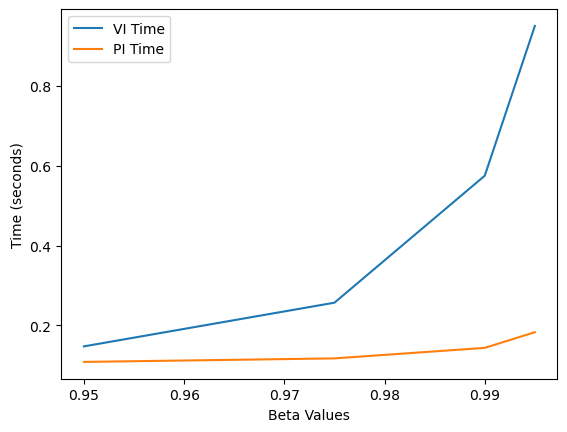

In [10]:
compare_methods()

`compare_methods()` uses the default `max_iter` of each function (500 for VI, 50 for PI). The check below confirms both are high enough at $N = 1000$: both methods reach the same value function and policy vector at every $\beta$, and the iteration counts from the reference implementations (the VI one above and a matching PI one) stay under those caps. Timings depend on the machine.

In [11]:
def pi_reference(pi_0, beta, N, u=np.sqrt, max_iter=1000):
    # Policy iteration with the number of iterations: evaluate with (19.7), improve with (19.5).
    w = np.linspace(0, 1, N+1)
    feasible = np.tri(N+1, dtype=bool)
    C = u(np.where(feasible, w[:, None] - w[None, :], 0))
    pi = np.asarray(pi_0)
    for k in range(1, max_iter+1):
        V = np.zeros(N+1)
        for i in range(1, N+1):
            V[i] = C[i, pi[i]] + beta*V[pi[i]]
        new = np.where(feasible, C + beta*V[None, :], -np.inf).argmax(axis=1)
        if np.array_equal(new, pi):
            return V, k
        pi = new
    raise RuntimeError("no convergence")

N = 1000
w = np.linspace(0, 1, N+1)
pi_0 = np.arange(-1, N)
pi_0[0] = 0
print("  beta   VI iterations   PI iterations   periods   V*(W_max)")
for beta in [.95, .975, .99, .995]:
    V_vi, c_vi = value_iteration(np.sqrt(w), beta, N)
    V_pi, c_pi = policy_iteration(pi_0, beta, N)
    _, k_vi = vi_reference(np.sqrt(w), beta, N)
    V_ref, k_pi = pi_reference(pi_0, beta, N)
    print(f"{beta:6}   {k_vi:13d}   {k_pi:13d}   {len(c_pi):7d}   {V_pi[-1]:9.4f}")
    assert np.allclose(V_vi, V_pi) and np.allclose(V_pi, V_ref) and c_vi == c_pi
    assert k_vi < 500 and k_pi < 50

  beta   VI iterations   PI iterations   periods   V*(W_max)


  0.95              59              20        59      3.1962


 0.975             105              21       105      4.4823


  0.99             217              26       217      7.0170


 0.995             364              32       364      9.8085


Value iteration needs more iterations as $\beta$ approaches 1, and each one is a full maximization over the $(N+1) \times (N+1)$ grid. Policy iteration needs only 20 to 32 policy updates across these $\beta$, so its time grows much more slowly.